# Lab 1:  

   ## 1.1 Image in Python

   ## 1.2 Image Manipulation
   
   ## 1.3 Image Statistics
   
   ## 1.4 Lab Assignment: Lane Detection

### Objective: 
1. Understanding image manipulation in Python
2. Knowing different color spaces and how/when to use them



### Outcome/Submission
1. Jupyter notebook with 
    - Completed functions along with comments.
    - Visualization of the results in the notebook itself.  
    - Answers to the question asked in the notebook.  
___

2. Lane Detection:  
    - Code/function which generate the mask for lane along with comments on how you detected the yellow lanes.
    - Short answer on the limitation of the approch used for lane detection.
    - A output video 'detected_lane.mp4' with detected lane, the lane orientation and a warning when in incorrect lane.

## 1.1 Image in Python
Images are matrices and in Python best matrix library is Numpy.

Some of the Python libraries for image processing:

    - Scipy (scipy.ndimage)
    - Scikit-Image (skimage)
    - Python Imaging Library (PIL: in-built Python package)
    - OpenCV (we will use this)  
    
And many other are available. Most libraries uses or have conversion to and from Numpy arrays.

Installation:

    - Numpy (pip install numpy)
    - OpenCV (pip install opencv-python)
    - Scikit-Image (pip install -U scikit-image)
    - Scipy (pip install scipy)
    - Matplotlib (pip install matplotlib)

#### Tasks
1. Read "mandrill.tif" image using OpenCV's _imread_ function.
2. Visualize image using PIL.  
<span style="color:Red">Q1</span> Why image looks different?
3. Read "mandrill.tif" image as grey using OpenCV's imread function. [_imread_ flags](https://docs.opencv.org/3.4/d8/d6a/group__imgcodecs__flags.html) 
4. Write image with .jpg extension using OpenCV's _imwrite_ function.

In [37]:
### Importing packages
import cv2             #for image manipulation
import numpy as np     #for handling matrix operation
from PIL import Image  #for image visualization in Jupyter Notebook (matplotlib could also be used)
from typing import List, Tuple

In [38]:
mandrillImage = cv2.imread("mandrill.tif") #1
#https://www.geeksforgeeks.org/convert-opencv-image-to-pil-image-in-python/?ref=oin_asr1
colorCoverted = cv2.cvtColor(mandrillImage, cv2.COLOR_BGR2RGB) #2 from BGR to RGB 
mandrillImagePIL = Image.fromarray(colorCoverted)
mandrillImagePIL.show()

<span style="color:Red">Q1</span>: Images look different due to differences in color space representation between OpenCV (BGR) and PIL (RGB).

In [39]:
mandrillImageGrey = cv2.imread("mandrill.tif", cv2.IMREAD_GRAYSCALE) #3
cv2.imwrite("mandrillGrey.jpg", mandrillImageGrey) #4

True

## 1.2 Image Manipulation
   ### 1.2.1 Image Info
   ### 1.2.2 Colorspace Conversion
   ### 1.2.3 Image Cropping
   ### 1.2.4 Image Rotation
   ### 1.2.5 Image Filters

### 1.2.1 Image Info 

#### Tasks
1. Read "mandrill.tif" image and print image informations:  
    - number of dimensions 
    - image shape
    - datatype of image pixel
    - datatype of image

In [40]:
### Image (matrix) Basic Info
img = cv2.imread("mandrill.tif", cv2.IMREAD_COLOR)

ndim = img.ndim
shape = img.shape
dtype = img.dtype
data_type = type(img)

print("number of dimensions: " + str(ndim))
print("image shape: " + str(shape))
print("datatype of image pixel: " + str(ndim))
print("datatype of image: " + str(ndim))

number of dimensions: 3
image shape: (256, 256, 3)
datatype of image pixel: 3
datatype of image: 3


### 1.2.2 Colorspace Conversion

#### Tasks  
1. Read "mandrill.tif" as gray image using *cv2.imread* with _cv2.IMREAD_GRAYSCALE_.
2. Read "mandrill.tif" as color image and convert to gray image using *cv2.cvtColor* function.  
<span style="color:Red">Q2</span> Are the two gray image same? If not, why?

3. Check the colorspaces available in OpenCV library. Try few conversion and visualize the images in different color spaces. Focus specially on RGB and HSV colorspaces.  
<span style="color:Red">Q3</span> When would you use RGB and HSV color spaces?

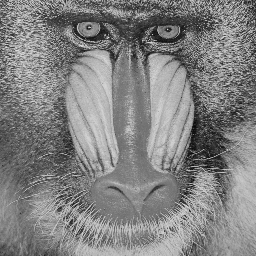

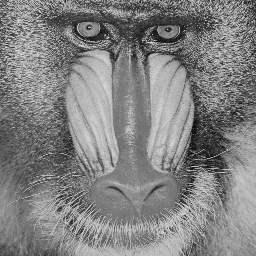

False


In [41]:
mandrillImageGrey = cv2.imread("mandrill.tif", cv2.IMREAD_GRAYSCALE) #1 (#3 in task 1.1)
mandrillImage = cv2.imread("mandrill.tif", cv2.IMREAD_COLOR) #2 (task 1.2.1)
mandrillImageConverted = cv2.cvtColor(mandrillImage, cv2.COLOR_BGR2GRAY)

#cv2.imshow("mandrillImageGrey",mandrillImageGrey)
#cv2.imshow("mandrillImageConverted", mandrillImageConverted)
display(Image.fromarray(mandrillImageGrey))
display(Image.fromarray(mandrillImageConverted))

print((mandrillImageGrey == mandrillImageConverted).all())

<span style="color:Red">Q2</span>: Although not visible by eye, they are not the same. cv2.IMREAD_GRAYSCALE reads the image directly in grayscale by interpreting pixel values as intensity values without going through RGB channels. cv2.cvtColor converts from the original BGR color channels to grayscale by averaging or weighting the color channels

'HSV'

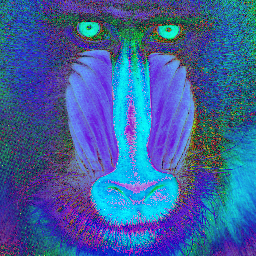

'RGB'

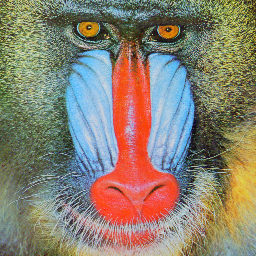

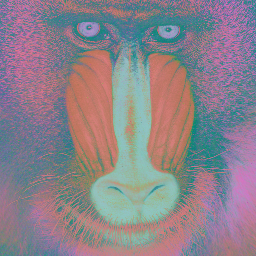

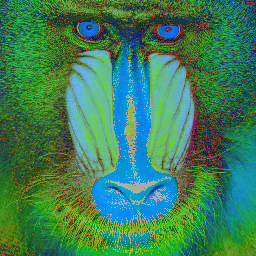

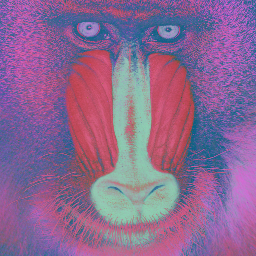

In [42]:
mandrillImageHSV = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) #3
mandrillImageRGB = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
mandrillImageLAB = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
mandrillImageHLS = cv2.cvtColor(img, cv2.COLOR_BGR2HLS)
mandrillImageLUV = cv2.cvtColor(img, cv2.COLOR_BGR2LUV)
#cv2.imshow("mandrillImageHSV",mandrillImageHSV)

display("HSV",Image.fromarray(mandrillImageHSV))
display("RGB",Image.fromarray(mandrillImageRGB))
display(Image.fromarray(mandrillImageLAB))
display(Image.fromarray(mandrillImageHLS))
display(Image.fromarray(mandrillImageLUV))


 <span style="color:Red">Q3</span>: RGB is the more realistic out of the two, but does not seperate color from intensity. HSV seperates color from intensity. I would use HSV when seperating color from intensity is required else RGB.

### 1.2.3 Image Cropping  
1. Implement and test two simple Python functions for center crop and random crop keeping same aspect ratio. (Used in image augmentation for deep learning)

    ```
    def center_crop(image:np.ndarray, ratio:float)->np.ndarray:  
        ...
    ```



    ```
    def random_crop(image:np.ndarray, ratio:float)->np.ndarray:  
        ...
    ```
    
*You can use **random** or **numpy.random** module to generate random numbers.*

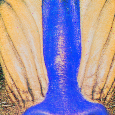

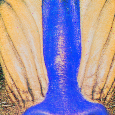

In [43]:
def center_crop(image:np.ndarray, ratio:float)->np.ndarray:  
    h, w = image.shape[:2]
    crop_h, crop_w = int(h * ratio), int(w * ratio)
    start_x, start_y = (w - crop_w) // 2, (h - crop_h) // 2
    return image[start_y:start_y + crop_h, start_x:start_x + crop_w]
    
    
def random_crop(image:np.ndarray, ratio:float)->np.ndarray:  
    h, w = image.shape[:2]
    crop_h, crop_w = int(h * ratio), int(w * ratio)
    start_x = np.random.randint(0, w - crop_w)
    start_y = np.random.randint(0, h - crop_h)
    return image[start_y:start_y + crop_h, start_x:start_x + crop_w]

centerCropImg = center_crop(img, 0.45)
randomCropImg = center_crop(img, 0.45)

display(Image.fromarray(centerCropImg))
display(Image.fromarray(randomCropImg))

### 1.2.4 Image Rotation  

#### Tasks
1. Implement a Python function to rotate the image by $\theta$ degrees in clockwise or anti-clockwise direction.  
```
def getRotation2DMatrix(theta: float)->np.ndarray:
    '''
    theta: angle of rotation in degress
    '''
    ...
   
   
def imrotate(image:np.ndarray, theta:  float)->np.ndarray:
    '''
    image: numpy array
    theta: angle of rotation in degress
    '''
    ...
```

2. Rotate the image by 30° clockwise around image center and visualize the image.   
<span style="color:Red">Q4</span> Is the image rotation as you expected? If not, what went wrong and how to correct it. 

Hint: 
<img title="a title" alt="Alt text" src="image_axis.png" width="300" height="300">

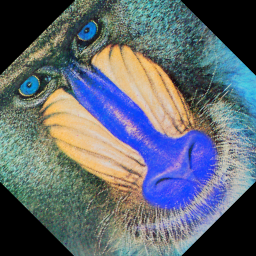

In [44]:
def getRotation2DMatrix(theta: float)->np.ndarray:
    '''
    theta: angle of rotation in degress
    '''
    theta_rad = np.radians(theta)
    cos, sin = np.cos(theta_rad), np.sin(theta_rad)
    return np.array([[cos, -sin], [sin, cos]])
   
   
def imrotate(image:np.ndarray, theta:  float)->np.ndarray:
    '''
    image: numpy array
    theta: angle of rotation in degress
    '''
    h, w = image.shape[:2]
    center = (w // 2, h // 2)
    matrix = cv2.getRotationMatrix2D(center, theta, 1.0)
    return cv2.warpAffine(image, matrix, (w, h))

rotatedImg = imrotate(img, 45)
display(Image.fromarray(rotatedImg))

   <span style="color:Red">Q4</span>: As expected.

3. Use the provided function **rotate_image** created using OpenCV's inbuilt functions to rotate the image.
    - rotate the image 4 times by 90°.
    - rotate the image 8 times by 45°.
    - rotate the image 36 times by 10°.     
    
    <span style="color:Red">Q5</span> Visualize the image after each step and report the observations.
    
*You can also try the **scipy.ndimage.rotate** function*

In [45]:
def rotate_image(image: np.ndarray, theta: float)->np.ndarray:
    image_center = tuple(np.array(image.shape[1::-1]) / 2)
    rot_mat = cv2.getRotationMatrix2D(image_center, theta, 1.0) #angle? -> not defined, should be theta
    result = cv2.warpAffine(image, rot_mat, image.shape[1::-1], flags=cv2.INTER_LINEAR)
    return result

def visualize_rotate_image(image, rotationStep):
    angle = 0
    while angle < 360:
        image = rotate_image(image, rotationStep)
        display(Image.fromarray(image))
        angle += rotationStep


# Uncomment to visualize
#visualize_rotate_image(img, 90)
#visualize_rotate_image(img, 45)
#visualize_rotate_image(img, 10)


<span style="color:Red">Q5</span>: We lose information with every rotation. In particular, if we rotate it by only 10° at a time, we can see that the edges of the image are cut off and it now looks like a circle. It also looks less blurred. The same goes for the 45° version, although we lose less information there. In the 90° version we do not see these effects, it looks the same after it has been fully rotated once.

### 1.2.5 Image Filters
Some of the commom filters:

<img title="a title" alt="Alt text" src="https://media.geeksforgeeks.org/wp-content/uploads/20211027143743/Typesofkernels.png" width="500" height="400">

#### Tasks
1. Write a kernel and apply to an image using **cv2.filter2D** and visualize the result.  
2. Write a simplified function to generate a motion blur and Gaussian blur kernel.
```
def create_motion_blur_kernel(ksize:Tuple[int,int], theta:float)->np.ndarray:
    '''
    ksize: kernel size, tuple of int
    theta: angle in degrees
    '''
    ...
```

```
def create_gaussian_blur_kernel(ksize:Tuple[int,int], sigma:float)->np.ndarray:
    '''
    ksize: kernel size, tuple of int
    sigma: standard deviation
    '''
    ...
```
<img title="Gaussian Kernel" alt="Gaussian Kernel" src="https://wikimedia.org/api/rest_v1/media/math/render/svg/c35de83757f2e4b6bf6cc570ada72ada21705b23" width="250" height="200">

3. Apply [Laplacian filter](https://homepages.inf.ed.ac.uk/rbf/HIPR2/log.htm) to *peppers.png* image and display the results.  
    <span style="color:Red">Q6</span> Why does the Laplacian make the peppers so shiny?
    - Run the filter on Gaussian blurred image. Do you observer the same effect?
     
     
4. Try out OpenCV's Canny edge detection. We will use it in the final part of lab. 

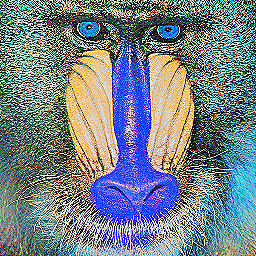

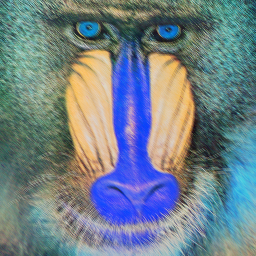

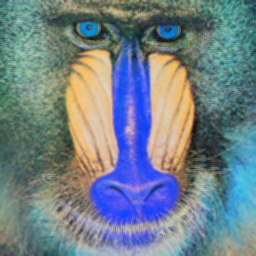

In [46]:
def create_motion_blur_kernel(ksize:Tuple[int,int], theta:float)->np.ndarray:
    '''
    ksize: kernel size, tuple of int
    theta: angle in degrees
    '''
    #box_blur_kernel = np.ones(ksize) / (ksize[0] * ksize[1])
    
    motion_blur_kernel = np.zeros(ksize)
    theta = np.deg2rad(theta)

    for x in range(ksize[1]):
        for y in range(ksize[0]):
            if abs((x - ksize[1] // 2) * np.sin(theta) - (y - ksize[0] // 2) * np.cos(theta)) < 0.5:
                motion_blur_kernel[y, x] = 1

    return motion_blur_kernel / motion_blur_kernel.sum() # normalize
    
    
def create_gaussian_blur_kernel(ksize:Tuple[int,int], sigma:float)->np.ndarray:
    '''
    ksize: kernel size, check for odd number
    sigma: standard deviation
    '''
    # check if the ksize is odd
    if ksize[0] % 2 == 0 or ksize[1] % 2 == 0:
        raise ValueError("ksize is even")

    gaussian_blur_kernel = np.zeros(ksize)
    padSizeX = ksize[1] // 2
    padSizeY = ksize[0] // 2 

    for s in range(-padSizeY, padSizeY + 1):
        for t in range(-padSizeX, padSizeX + 1):
            gf = np.exp(-(s**2 + t**2) / (2 * sigma**2)) # formula from gaussianfilter.m
            gaussian_blur_kernel[s + padSizeY, t + padSizeX] = gf

    return gaussian_blur_kernel / gaussian_blur_kernel.sum() # normalize

#1
sharpenKernel = np.array([[0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]])

sharpenKernelImg = cv2.filter2D(img, -1 ,sharpenKernel)

display(Image.fromarray(sharpenKernelImg))


#2
motionBlurKernelImg = cv2.filter2D(img, -1 ,create_motion_blur_kernel([3,3],45))
gaussianBlurKernelImg = cv2.filter2D(img, -1 ,create_gaussian_blur_kernel([3,3],45))

display(Image.fromarray(motionBlurKernelImg))
display(Image.fromarray(gaussianBlurKernelImg))

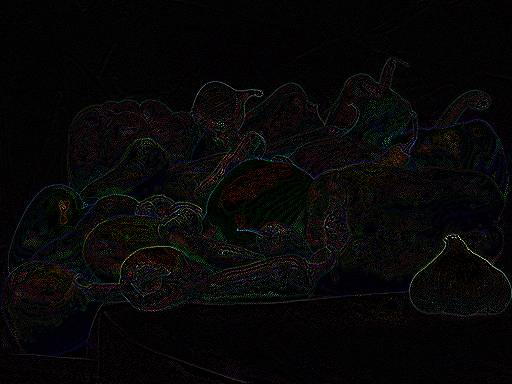

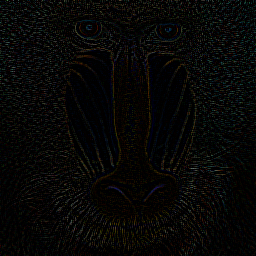

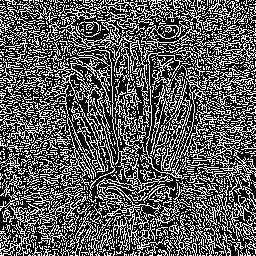

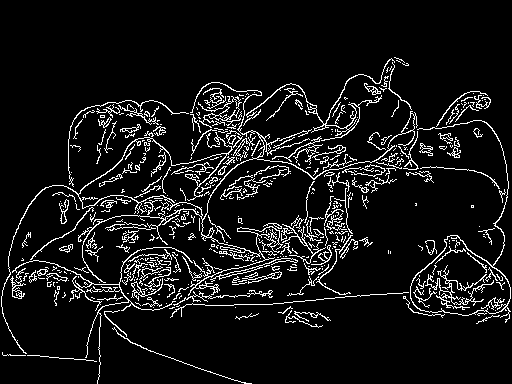

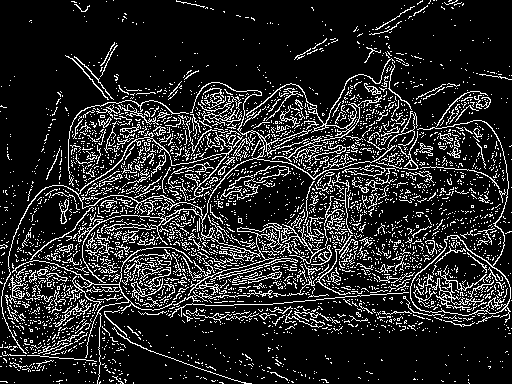

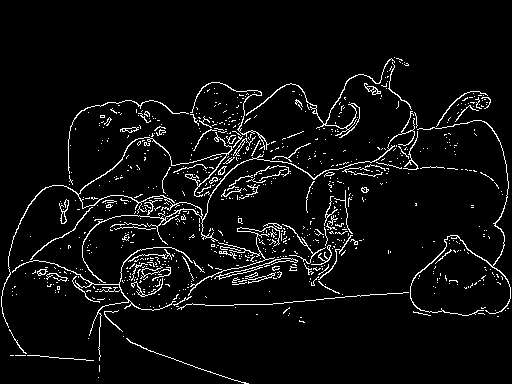

In [47]:
#3
peppersImg = cv2.imread("pepper.png", cv2.IMREAD_COLOR)

laplacianPeppersImg = cv2.Laplacian(peppersImg, -1)

display(Image.fromarray(laplacianPeppersImg))

laplacianGaussianBlurKernelImg = cv2.Laplacian(gaussianBlurKernelImg, -1)

display(Image.fromarray(laplacianGaussianBlurKernelImg))


#4

display(Image.fromarray(cv2.Canny(img, 50, 150)))
display(Image.fromarray(cv2.Canny(peppersImg, 50, 150)))
display(Image.fromarray(cv2.Canny(peppersImg, 50, 50)))
display(Image.fromarray(cv2.Canny(peppersImg, 150, 150)))


<span style="color:Red">Q6</span>: Laplacian accenturates areas with sharp intensity gradients like edges or the surface of the peppers. We do get less of that effect for the blurred image. 


## Image Statistics

Some of the image statistocs are mean, covarience, pixel count, histogram, and many other. Checkout [slides](https://userpages.cs.umbc.edu/caban1/Fall2010/CMSC691/Schedule_files/Docs/08-ImageStatistics.pdf) for more details.

#### Image Histogram
- Distribution of color intensity in the image
- Useful for guessing exposure and contarst in image
- Useful in contrast correction using [Histogram Equalization](https://en.wikipedia.org/wiki/Histogram_equalization).
    
#### Tasks
1. Use *matplotlib.pyplot* to plot the histogram of "boat.tif" image.
2. Write a function for histogram equalization and compare it with **cv2.equalizeHist** function.  
    <span style="color:Red">Q7</span> How to apply custom histogram equalization function or **cv2.equalizeHist** on color images.
    
```
def histogram_equalization(image: np.ndarray)->np.ndarray:
    '''
    image: grayscale image
    '''
    ...
```
    
*Hint: Create an array of size 256 that gives a new intensity value where the original intensity value are used as index.*

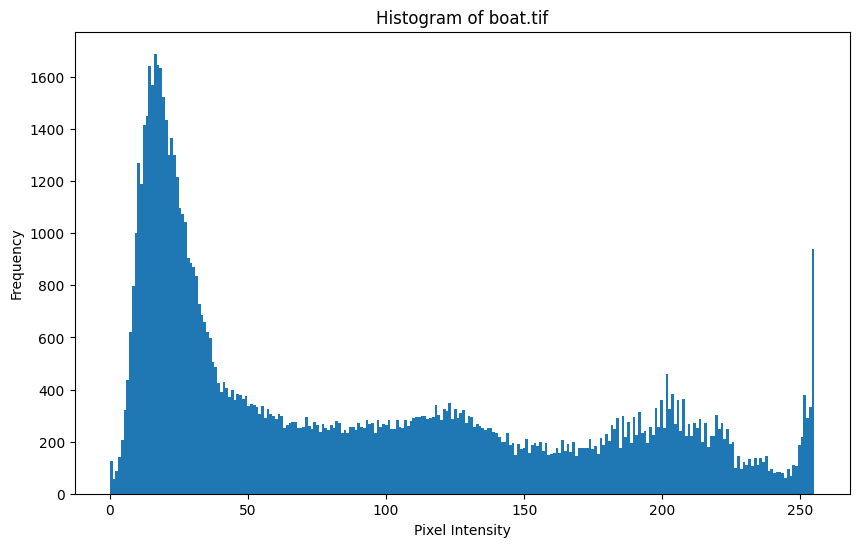

In [48]:
def histogram_equalization(image: np.ndarray)->np.ndarray:
    
    hist, _ = np.histogram(image.flatten(), 256, [0, 256])
    cdf = hist.cumsum()
    cdfMa = np.ma.masked_equal(cdf, 0)
      
    cdfMa = (cdfMa - cdfMa.min()) * 255 / (cdfMa.max() - cdfMa.min())  
    cdf = np.ma.filled(cdfMa, 0).astype('uint8')

    return cdf[image]


import matplotlib.pyplot as plt

boatImg = cv2.imread("boat.tif", cv2.IMREAD_GRAYSCALE)

#1
plt.figure(figsize=(10, 6))
plt.hist(boatImg.ravel(), bins=256) # better than hint
plt.title("Histogram of boat.tif")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

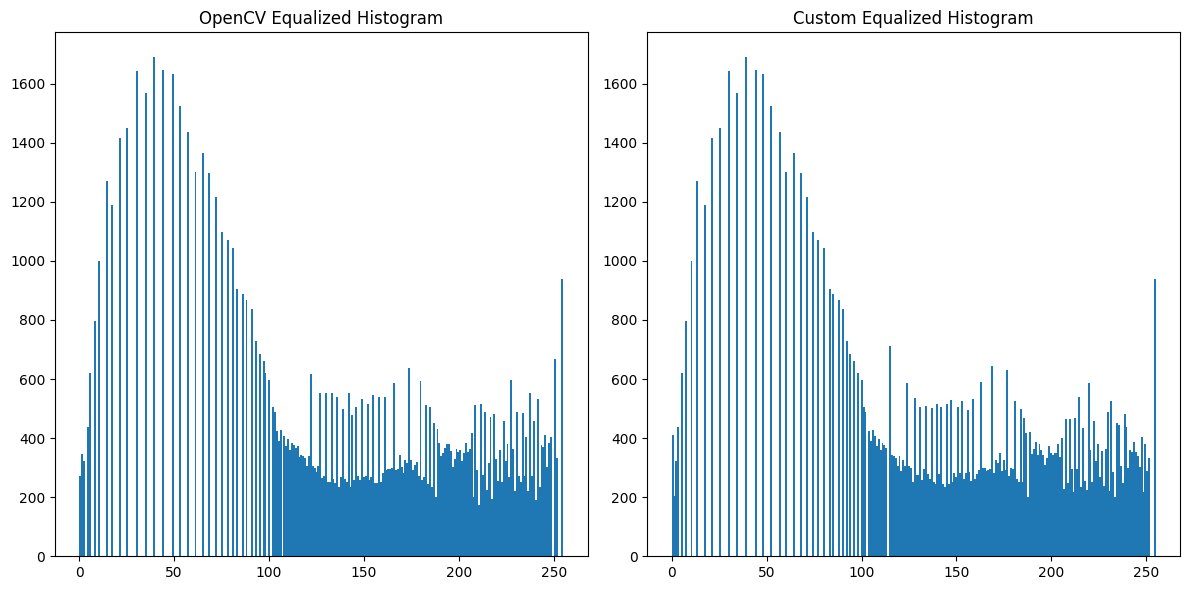

In [49]:
cv2HistogramEqualizationImg = cv2.equalizeHist(boatImg)
customHistogramEqualizationImg = histogram_equalization(boatImg)

plt.figure(figsize=(12, 6))


plt.subplot(1,2,1)
plt.hist(cv2HistogramEqualizationImg.ravel(), bins=256)
plt.title("OpenCV Equalized Histogram")

plt.subplot(1,2,2)
plt.hist(customHistogramEqualizationImg.ravel(), bins=256)
plt.title("Custom Equalized Histogram")

plt.tight_layout()
plt.show()


<span style="color:Red">Q7</span>: Since color images have multiple channels, we process each channel individually and apply the fucntion to each channel.

## Lab Assignment: Lane Detection

Lane detection is essential for autonomous vehicle to maintain lanes and avoid drifting. Hence, in this assigment we will detect yellow lane in the video provided and estimate the drift using the classical computer vision techniqes (color detection, edge detection, etc) and basic maths. 

A sample image:

<img title="lane_detection" alt="road" src="lane_detection.jpg" width="500" height="400">

In [50]:
def detect_yellow_lane(image: np.ndarray)->np.ndarray:
    '''
    code to detect the mask of yellow lane.
    
    image: input image frame
    ___
    output: image mask of yellow lane
    '''
    hsvImage = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Range of yellow, adjusted based on experimenting
    lowerYellow = np.array([20, 100, 100])
    upperYellow = np.array([40, 255, 255])

    return cv2.inRange(hsvImage, lowerYellow, upperYellow)
    

def orientation_estimation(mask: np.ndarray)->float:
    '''
    Function to estimate the orientation of yellow lane given the mask.
         /
    ____/______ : theta = 60
    
    mask: mask of yellow lane
    __________________________
    theta: angle in degrees [0-180] of yellow lane wrt horizontal axis
    '''
    lines = cv2.HoughLinesP(mask, 1, np.pi / 180, 100, minLineLength=50, maxLineGap=10)

    if lines is not None:
        # Calculate the angle of the first detected line
        x1, y1, x2, y2 = lines[0][0]
        angle = np.arctan2(y2 - y1, x2 - x1) * 180 / np.pi
        return angle
    else:
        return 0  # No line detected

    
def is_crossing_yellow_lane(orientation:float)->str:
    '''
    Function to decide if the vehicle is driving in current lane, crossing yellow lane, or crossed the yello lane.
    
    
    '''
    if orientation <= 2:
        return "Driving in Current Lane"  
    elif 2 < orientation <= 7:
        return "Crossing Yellow Lane"
    else:
        return "Crossed the Yellow Lane"
    
    
    
def draw_frame(image: np.ndarray, mask:np.ndarray, theta:float)->np.ndarray:
    '''
    Function to write a frame with mask information, orientation, and the warning.
    
    image: input image frame
    mask: mask of yellow lane
    theta: angle in degrees of yellow lane wrt horizontal axis
    __________________________
    output: output frame
    '''
    # Overlay the mask on the image (in a transparent way)
    mask_colored = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    masked_image = cv2.addWeighted(image, 1, mask_colored, 0.7, 0)

    # Add the angle text on the image
    font = cv2.FONT_HERSHEY_SIMPLEX
    angle_text = f"Orientation: {theta:.2f} degrees"
    cv2.putText(masked_image, angle_text, (10, 50), font, 1, (0, 255, 0), 2)

    # Add the crossing status text
    status = is_crossing_yellow_lane(theta)
    cv2.putText(masked_image, status, (10, 100), font, 1, (0, 0, 255), 2)

    return masked_image

In [51]:
vid_cap = cv2.VideoCapture("yellow_lane.mp4")

# Video Info
num_frames = int(vid_cap.get(cv2.CAP_PROP_FRAME_COUNT))
H = int(vid_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
W = int(vid_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
fps = vid_cap.get(cv2.CAP_PROP_FPS)

# Create video writer to save the processed video
vid_writer = cv2.VideoWriter("result_video.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

for i in range(num_frames):
    ret, frame = vid_cap.read()
    if ret:
        # Detect yellow lane mask
        yellow_lane_mask = detect_yellow_lane(frame)

        # Estimate the orientation of the lane
        orientation = orientation_estimation(yellow_lane_mask)

        # Draw the frame with mask and orientation info
        processed_frame = draw_frame(frame, yellow_lane_mask, orientation)

        # Write the processed frame to the output video
        vid_writer.write(processed_frame)

# Release the video capture and writer objects
vid_cap.release()
vid_writer.release()

In [52]:
### Working with videos using OpenCV
#vid_cap = cv2.VideoCapture("/path/to/video.mp4")

## Video Info
#num_frames = vid_cap.get(cv2.CAP_PROP_FRAME_COUNT)
#H = int(vid_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
#W = int(vid_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
#fps = vid_cap.get(cv2.CAP_PROP_FPS)

#vid_writer = cv2.VideoWriter("/path/to/save_result_video.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
#for i in range(num_frames):
    #ret, frame = vid_cap.read() # ret: bool if the frame is availbale, frame: image in BGR format 
    #if ret:
        ### detect yellow line mask
        ### estimate line orientation
        #...
        
        ### Write information to the image
        #vid_writer.write(frame_processed)